<a href="https://colab.research.google.com/github/TWAPZCODE/Quant-Research/blob/main/Volatility_Regime_Classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

The code below loads the required libraries. yfinance to pull price data, pandas/numpy for data handling, matplotlib for charts, and scikit-learn for the models and evaluation metrics

In [70]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import TimeSeriesSplit
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
       accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
)

In [71]:
# Shared chart style — applied once, used by every visualization below
plt.rcParams.update({
    "figure.dpi": 110,
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.edgecolor": "#444444",
    "axes.linewidth": 0.8,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "--",
    "legend.frameon": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
})

# Consistent color palette used across all charts
PALETTE = {
    "primary": "#2C6E91",    # steel blue — main series
    "secondary": "#E28743",  # warm orange — accent / highlight
    "tertiary": "#4C9A78",   # muted green — third series
    "danger": "#C6564B",     # muted red — threshold / high-vol
    "neutral": "#8C8C8C",    # gray — reference lines
}

def clean_axes(ax):
    """Remove top/right spines for a cleaner look."""
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

The Data parameters and Target parameters set the knobs for the whle notebook. The ticker, what date range, how far ahead we're forecasting volatility (vol_lookahead), and which lookback windows we use to build volatiltiy features.

Change these values here and everything following adjusts as well.

In [72]:
# Data parameters
ticker = "QQQ"
start = "2010-01-01"
end = "2025-01-01"

# Target parameters
vol_lookahead = 10    # days forward to measure realized volatility over
vol_lookback_windows = [5, 10, 20] # backward-looking vol features (days)

In [73]:
data = yf.download(ticker, start=start, end=end, auto_adjust=True)
data.columns = data.columns.get_level_values(0) if isinstance(data.columns, pd.MultiIndex) else data.columns
data = data.dropna()
data.head()

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Date,,,,,
2010-01-04,40.246574,40.307268,40.116525,40.168547,62822800
2010-01-05,40.246574,40.315937,40.021153,40.220565,62935600
2010-01-06,40.003807,40.359281,39.943117,40.229231,96033000
2010-01-07,40.029812,40.116515,39.813060,40.064493,77094100
2010-01-08,40.359280,40.359280,39.821735,39.943116,88886600


The visualisation is to make sure the closing price over the whole period is represented.

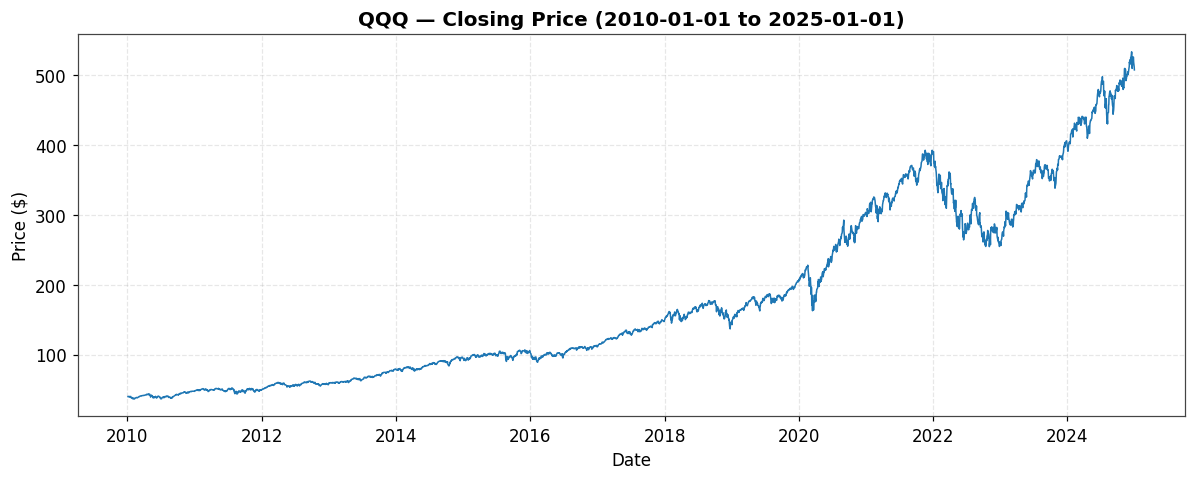

In [74]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(data.index, data["Close"], color=PALETTE["primary"], linewidth=1.3)
ax.set_title(f"{ticker} — Closing Price ({start} to {end})")
ax.set_xlabel("Date")
ax.set_ylabel("Price ($)")
ax.grid(axis="y")
clean_axes(ax)
plt.tight_layout()
plt.show()

The following builds the models input features- all calculated using only past data (nothing here looks into the future);


*   realized_vol_5d/10d/20d- how volatile price has been at the three lookback lengths
*   ret_5d/10d/20d- recent momentum
*   atr_14- average true range, a vol measure based on daily high/low range
*   rsi_14- a momentum oscillator (overbought/oversold signal)
*   volume_change_5d- how trading volume has shifted recently










In [75]:
df = data.copy()

# Daily log returns
df["log_ret"] = np.log(df["Close"] / df["Close"].shift(1))

# Backward-looking realized volatility features (annualised)
for w in vol_lookback_windows:
      df[f"realized_vol_{w}d"] = df["log_ret"].rolling(w).std() * np.sqrt(252)

# Momentum / returns
df["ret_5d"] = df["Close"].pct_change(5)
df["ret_10d"] = df["Close"].pct_change(10)
df["ret_20d"] = df["Close"].pct_change(20)

# Average True Range (ATR) - volatility of price range
high_low = df["High"] - df["Low"]
high_close = (df["High"] - df["Close"].shift()).abs()
low_close = (df["Low"] - df["Close"].shift()).abs()
true_ranges = pd.concat([high_low, high_close, low_close], axis=1).max(axis=1)
df["atr_14"] = true_ranges.rolling(14).mean()

# RSI (14-day)
delta = df["Close"].diff()
gain = delta.clip(lower=0).rolling(14).mean()
loss = (-delta.clip(upper=0)).rolling(14).mean()
rs = gain / loss
df["rsi_14"] = 100 - (100 / (1 + rs))

# Volume change
df["volume_change_5d"] = df["Volume"].pct_change(5)

df.head()
df.tail()

Price,Close,High,Low,Open,Volume,log_ret,realized_vol_5d,realized_vol_10d,realized_vol_20d,ret_5d,ret_10d,ret_20d,atr_14,rsi_14,volume_change_5d
Date,,,,,,,,,,,,,,,
2024-12-24,526.043762,526.133063,520.316382,520.951667,17558200,0.013469,0.327603,0.254987,0.194624,-0.009304,0.019621,0.047819,7.921226,54.902115,-0.385628
2024-12-26,525.686279,527.314174,522.420614,524.415770,19090500,-0.000680,0.120019,0.239311,0.194561,0.027076,0.001008,0.041515,8.085306,55.689442,-0.651017
2024-12-27,518.698364,522.559632,514.033084,522.122881,33839600,-0.013382,0.171563,0.247014,0.199189,0.017956,-0.005883,0.035825,8.570118,48.036106,-0.271355
2024-12-30,511.799683,515.521971,508.047618,511.700446,34584000,-0.013389,0.199311,0.249953,0.204321,-0.004278,-0.026556,0.013147,8.958549,46.343592,-0.428647
2024-12-31,507.452087,513.834533,506.489254,513.080200,29117000,-0.008531,0.179535,0.232143,0.203086,-0.022262,-0.048527,-0.006279,9.042917,44.902078,-0.018731


Below, a chart of the three realized volatility features over time.

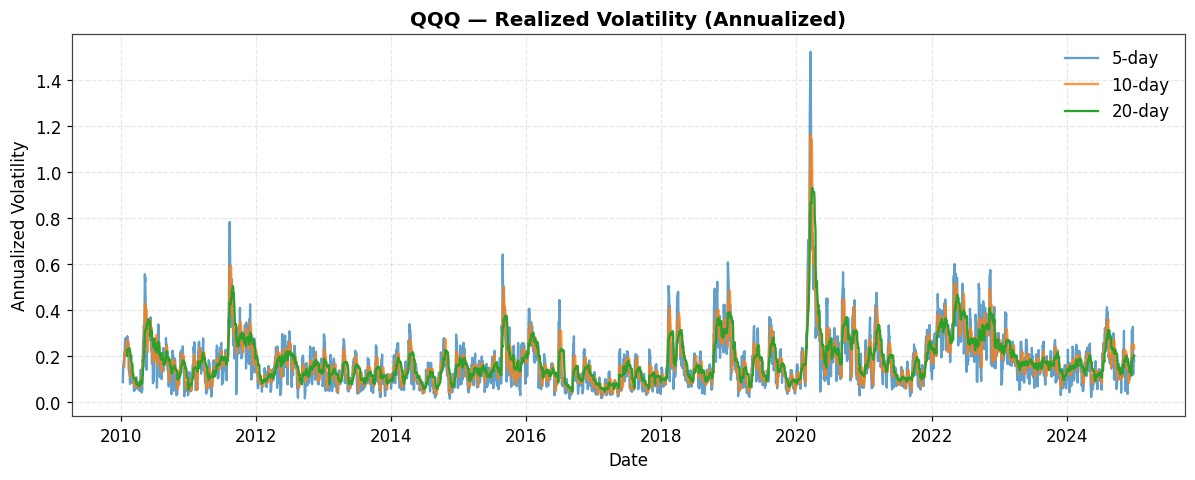

In [76]:
plt.figure(figsize=(11, 4.5))
plt.plot(df.index, df["realized_vol_5d"], label="5-day", alpha=0.7)
plt.plot(df.index, df["realized_vol_10d"], label="10-day", alpha=0.8)
plt.plot(df.index, df["realized_vol_20d"], label="20-day", linewidth=1.5)
plt.title(f"{ticker} — Realized Volatility (Annualized)")
plt.xlabel("Date")
plt.ylabel("Annualized Volatility")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The following creates the label the model will learn to predict - whather the next 10 days will be a High or Low volatility regime, using the median forward volatility as a cutoff.


In [77]:
future_log_ret = df["log_ret"].shift(-1)  #returns starting the day AFTER today
forward_vol = future_log_ret.rolling(vol_lookahead).std().shift(-(vol_lookahead - 1)) * np.sqrt(252)
df["forward_vol"] = forward_vol

# Binary target: High vol regime (1) vs Low vol regime (0), split at medium
vol_mean = df["forward_vol"].median()
df["target"] = (df["forward_vol"] > vol_mean).astype(int)

print(f"Median forward volatility threshold: {vol_mean:.2%}")
df[["Close", "forward_vol", "target"]].tail(15)

Median forward volatility threshold: 15.42%


Price,Close,forward_vol,target
Date,,,
2024-12-10,515.920898,0.254987,1
2024-12-11,525.157166,0.239311,1
2024-12-12,521.767944,0.247014,1
2024-12-13,525.761780,0.249953,1
2024-12-16,533.332947,0.232143,1
2024-12-17,530.984253,NaN,0
2024-12-18,511.828033,NaN,0
2024-12-19,509.548737,NaN,0
2024-12-20,513.998352,NaN,0


Two charts below:

1. The distribution of forward volatility, with the median threshold marked — this shows how the High/Low split actually divides the data.
2. The resulting class balance — since we split at the median, this should be close to a 50/50 split by construction.

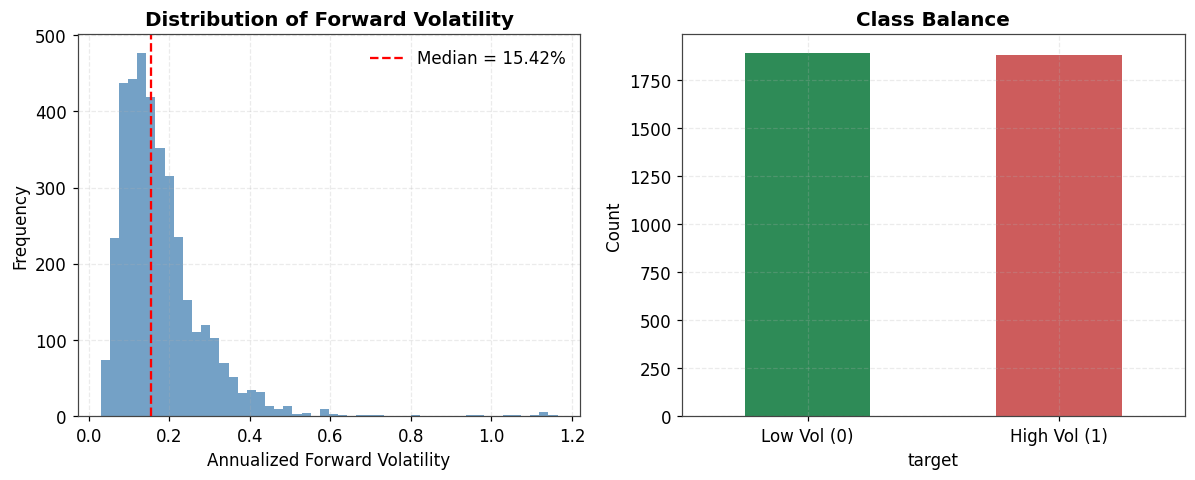

In [78]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].hist(df["forward_vol"].dropna(), bins=50, alpha=0.75, color="steelblue")
axes[0].axvline(vol_mean, color="red", linestyle="--", label=f"Median = {vol_mean:.2%}")
axes[0].set_title("Distribution of Forward Volatility")
axes[0].set_xlabel("Annualized Forward Volatility")
axes[0].set_ylabel("Frequency")
axes[0].legend()

df["target"].value_counts().sort_index().plot(
    kind="bar", ax=axes[1], color=["seagreen", "indianred"]
)
axes[1].set_xticklabels(["Low Vol (0)", "High Vol (1)"], rotation=0)
axes[1].set_title("Class Balance")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()